# GE Discovery MI (Listmode Reconstruction; With Time of Flight)

This tutorial demonstrates how to use PyTomography's algorithm for VOI based uncertainty estimation in PET reconstruction. The first part of the tutorial is the same as the introductory PET reconstruction tutorial for the discovery MI data. The data here can be downloaded from https://zenodo.org/records/8404015

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GE-DMI-NEMA")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GE-DMI-NEMA")
GE_DATA = DATA / 'PET' / 'GE-DMI-NEMA'

PET/GE-DMI-NEMA: already downloaded


In [2]:
import pytomography
from pytomography import io
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.algorithms import OSEM, BSREM
from pytomography.priors import RelativeDifferencePrior
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt
import torch
from pytomography.callbacks import DataStorageCallback

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`: the sensitivity image then goes through GE's 146 million valid crystal pairs in blocks that fit. Each reconstruction prints its estimate before it runs (`estimate_memory`). The tutorial peaks at about 11 GB (measured on Windows), most of it what it holds whatever the budget: the 49 million events with their corrections, the valid pairs with their weights, and PyTorch and CUDA themselves. A lower `RAM_GB` saves little: the tutorial needs about 11 GB however low it is.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 11 GB however low this is
pytomography.set_memory_budget(RAM_GB)

This code is from the introductory PET tutorial for discovery MI data

In [4]:
folder = GE_DATA / 'dmi_nema_lm'
# The listmode events, the object grid and the projection metadata (the scanner's info and its TOF bins)
detector_ids, object_meta, proj_meta = io.PET.read_ge_hdf5(
    folder / 'LIST0000.BLF',
    object_meta=ObjectMeta(dr=(2.78, 2.78, 2.78), shape=(192, 192, 71)) # mm, voxels
)
info = proj_meta.info


weights, additive_counts, detector_ids_sensitivity, weights_sensitivity = io.PET.read_ge_corrections(folder / 'corrections.h5')


# The projection metadata: the events, their TOF bins, and every valid crystal pair with its weight
proj_meta = PETLMProjMeta(
    detector_ids,
    info,
    tof_meta=proj_meta.tof_meta,
    detector_ids_sensitivity=detector_ids_sensitivity,
    weights_sensitivity=weights_sensitivity
    )

psf_transform = GaussianFilter(4.5) # 4.5mm gaussian psf
system_matrix = PETLMSystemMatrix(
    object_meta,
    proj_meta,
    obj2obj_transforms = [psf_transform],
    N_splits=8,
)
likelihood = PoissonLogLikelihood(
    system_matrix,
    additive_term=additive_counts/weights,
)

For uncertainty estimation, we to create a `DataStorageCallback` instance to store the reconstructed image for every iteration of reconstruction

In [5]:
recon_algorithm = OSEM(likelihood)
data_storage_callback = DataStorageCallback(likelihood, torch.clone(recon_algorithm.object_prediction))
print(recon_algorithm.estimate_memory(n_subsets=34)) # its peak RAM and GPU memory, before it runs (the callback's images come on top)
recon_OSEM = recon_algorithm(n_iters=2, n_subsets=34, callback=data_storage_callback)

OSEM (PETLMSystemMatrix): 34 subsets, memory budget 25 GB
Peak ~ 7.8 GB RAM, 2.1 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.6 GB RAM, 1.4 GB GPU (events and their projector order 0.8 GPU, sensitivity weights 0.6 RAM, sensitivity and normalisation images (34) 0.4 GPU, image, update and attenuation map 0.04 GPU, projections (the data) 0.00 GPU, additive term 0.2 GPU)
  one subset at a time: 0.00 GB RAM, 0.3 GB GPU (expected counts, ratio and temporaries (one subset) 0.02 GPU, positions of the subset's events 0.01 GPU, building a subset's projector order (its first projection) 0.3 GPU)
  projector chunks: 0.00 GB RAM, 0.01 GB GPU (projector chunk 0.01 GPU)
  Python, CUDA, allocator: 5.1 GB RAM, 0.4 GB GPU (Python, PyTorch and CUDA 3.7 RAM, PyTorch's GPU cache (rounded and kept blocks) 0.4 GPU, memory the allocators keep (Windows) 1.4 RAM)
To use less: 68 subsets ~ 8.1 GB RAM, 2.3 GB GPU, N_splits 16 ~ 7.7 GB RAM, 2.1 GB GPU
(plus whatever else your scrip

We can plot the reconstructed image, a transverse slice through the spheres with the bed at the bottom:

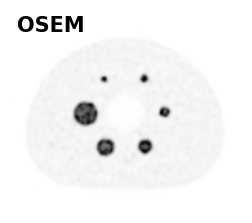

In [6]:
fig, ax = plt.subplots(1,1,figsize=(3,3))   
plt.sca(ax)
plt.imshow(recon_OSEM[:,:,20].T.cpu(), cmap='Greys', interpolation='gaussian', vmax=0.5)
plt.axis('off')
plt.text(0.03, 0.97, 'OSEM', color='black', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
plt.xlim(34,156)
plt.ylim(146,39)
plt.show()

Lets load masks of each of the NEMA spheres. The mask was drawn in 3D Slicer on this grid; `io.load_mask` reads it with its geometry, and `.on(object_meta, label=k)` gives the part of each voxel inside region `k`:

In [7]:
spheres = io.load_mask(GE_DATA / 'fdg_spheres.seg.nrrd')
masks = [spheres.on(object_meta, label=k) for k in range(1, 9)]

We can estimate the uncertainty on the largest sphere, corresponding to the first mask:

In [8]:
uncertainty_abs, uncertainty_pct = recon_algorithm.compute_uncertainty(
    mask = masks[0],
    data_storage_callback = data_storage_callback,
    return_pct = True,
)

In [9]:
print(f'Estimated uncertainty in large sphere: {uncertainty_pct:.2f}%')

Estimated uncertainty in large sphere: 1.63%


## Save the images

`io.save_dicom` writes the reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it. The list-mode files carry no patient frame, so the image is centred on the scanner's axis, where PyTomography reconstructs it.

In [10]:
saved = io.save_dicom(recon_OSEM, OUTPUT / 't_uncertainty_pet' / 'osem', object_meta, series_description='OSEM 2x34',
                      overwrite=True)